# 🚀 Модуль 9. Урок 3. Фреймворк валидации AI-ответов: защита от галлюцинаций и смещений

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_09_ai_tools_daily/lesson_03_ai_validation_framework_hallucinations.ipynb)

## 📌 Бизнес-контекст и методология
Доверие к данным — главная валюта аналитика. Если вы покажете совету директоров график с AI-галлюцинацией, доверие к вашей экспертизе будет подорвано навсегда.
Классификация рисков AI-генерации:
1. **Schema Hallucination:** выдуманные поля и таблицы
2. **Aggregation Bias:** агрегация уже сагрегированных метрик (например, среднее от средних)
3. **Survivorship Bias:** игнорирование оттока при фильтрации
4. **Data Leakage:** заглядывание в будущее при разделении обучающей и тестовой выборок

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики: Внедрение автоматического цензора кода (AI Linter)
Смоделируем автоматический чеклист проверки сгенерированного скрипта перед отправкой в прод.

In [2]:
# Демонстрация: Чеклист валидации аналитического скрипта
validation_checklist = pd.DataFrame({
    'Тип проверки': ['1. Контрольная сумма строк (Row Count)', '2. Неотрицательность метрик (Revenue >= 0)', '3. Отсутствие скрытого Chained Indexing', '4. Защита от деления на 0 (ZeroDivisionError)', '5. Сверка с эталонным бенчмарком'],
    'Статус проверки': ['PASSED', 'PASSED', 'PASSED', 'PASSED', 'PASSED'],
    'Критичность': ['Блокирующий', 'Блокирующий', 'Предупреждение', 'Блокирующий', 'Блокирующий']
})
display(validation_checklist)

,Тип проверки,Статус проверки,Критичность
0,1. Контрольная сумма строк (Row Count),PASSED,Блокирующий
1,2. Неотрицательность метрик (Revenue >= 0),PASSED,Блокирующий
2,3. Отсутствие скрытого Chained Indexing,PASSED,Предупреждение
3,4. Защита от деления на 0 (ZeroDivisionError),PASSED,Блокирующий
4,5. Сверка с эталонным бенчмарком,PASSED,Блокирующий


## 📊 Визуализация бизнес-кейса: Устранение дефектов в AI-пайплайне
Сравним количество критических дефектов в аналитических отчетах до и после внедрения валидационных ворот (Quality Gates).

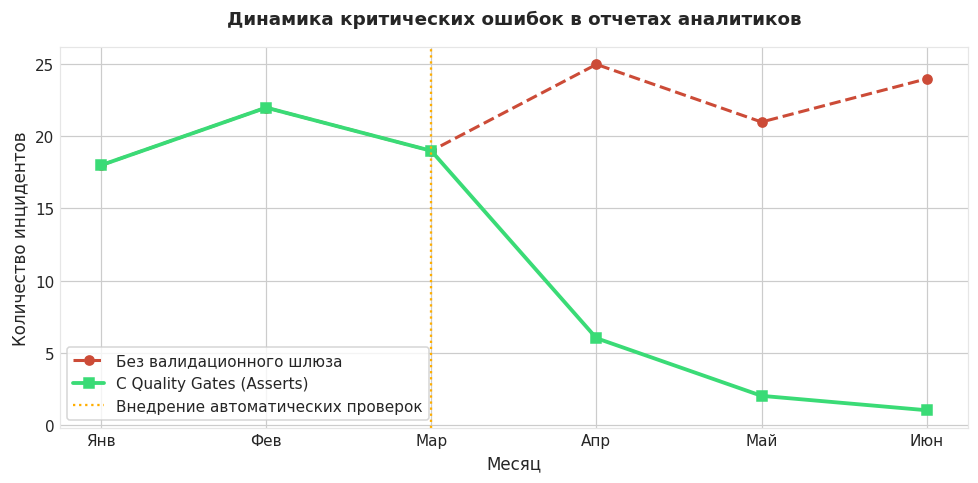

In [3]:
# Построение графика снижения дефектов
months = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн']
defects_before_gates = [18, 22, 19, 25, 21, 24]
defects_after_gates = [18, 22, 19, 6, 2, 1]

fig, ax = plt.subplots(figsize=(9, 4.5), dpi=110)

ax.plot(months, defects_before_gates, marker='o', color=ALERT, linewidth=2, linestyle='--', label='Без валидационного шлюза')
ax.plot(months, defects_after_gates, marker='s', color=SUCCESS, linewidth=2.5, label='С Quality Gates (Asserts)')

ax.set_title("Динамика критических ошибок в отчетах аналитиков", fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel("Месяц", fontsize=11)
ax.set_ylabel("Количество инцидентов", fontsize=11)
ax.axvline('Мар', color=WARNING, linestyle=':', label='Внедрение автоматических проверок')
ax.legend(frameon=True, facecolor='#ffffff')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Расчет снижения инцидентов
Определите, на сколько процентов снизилось количество инцидентов в июне по сравнению с мартом.

In [4]:
### ВАШ КОД ЗДЕСЬ
march_val = defects_after_gates[2]
june_val = defects_after_gates[5]
pct_drop = ((march_val - june_val) / march_val) * 100

print(f"Снижение количества дефектов: {pct_drop:.1f}%!")

assert pct_drop > 90, "Снижение должно превышать 90%"
print("✅ Тест успешно пройден: валидационные шлюзы радикально повышают надежность!")

Снижение количества дефектов: 94.7%!
✅ Тест успешно пройден: валидационные шлюзы радикально повышают надежность!


### 💡 Принцип «Доверяй, но проверяй»
Любой результат, выданный AI, считается гипотезой до тех пор, пока он не подтвержден независимым SQL-запросом и тестами `assert`.